In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ryuk495/dhaka-dataset/houserentdhaka.csv


In [2]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import matplotlib
matplotlib.rcParams["figure.figsize"] = (20,10)

In [3]:
df1 = pd.read_csv("/kaggle/input/datasets/ryuk495/dhaka-dataset/houserentdhaka.csv")
df1.head()

,Unnamed: 0,Location,Area,Bed,Bath,Price
0,0,"Block H, Bashundhara R-A, Dhaka","1,600 sqft",3,3,20 Thousand
1,1,"Farmgate, Tejgaon, Dhaka",900 sqft,2,2,20 Thousand
2,2,"Block B, Nobodoy Housing Society, Mohammadpur,...","1,250 sqft",3,3,18 Thousand
3,3,"Gulshan 1, Gulshan, Dhaka","2,200 sqft",3,4,75 Thousand
4,4,"Baridhara, Dhaka","2,200 sqft",3,3,75 Thousand


In [4]:
df2=df1.drop(['Unnamed: 0'], axis="columns")

In [5]:
df2.isnull().sum()

Location    0
Area        0
Bed         0
Bath        0
Price       0
dtype: int64

In [6]:
print(df2.duplicated().sum())

13541


In [7]:
df2[df2.duplicated(keep=False)]

,Location,Area,Bed,Bath,Price
1,"Farmgate, Tejgaon, Dhaka",900 sqft,2,2,20 Thousand
2,"Block B, Nobodoy Housing Society, Mohammadpur,...","1,250 sqft",3,3,18 Thousand
6,"Baridhara, Dhaka","2,300 sqft",3,3,75 Thousand
10,"Block D, Bashundhara R-A, Dhaka","1,300 sqft",3,3,40 Thousand
11,"Block J, Bashundhara R-A, Dhaka","1,250 sqft",3,3,19 Thousand
...,...,...,...,...,...
28787,"Sector 9, Uttara, Dhaka",900 sqft,2,2,18 Thousand
28788,"Sector 9, Uttara, Dhaka",900 sqft,2,2,18 Thousand
28791,"Block E, Banasree, Dhaka","1,000 sqft",3,3,16.5 Thousand
28794,"Kafrul, Dhaka",850 sqft,2,2,15 Thousand


In [8]:
df2=df2.drop_duplicates()
df2.shape

(15259, 5)

In [9]:
df2.Area.unique()

array(['1,600 sqft', '900 sqft', '1,250 sqft', '2,200 sqft', '3,000 sqft',
       '2,300 sqft', '950 sqft', '1,150 sqft', '1,300 sqft', '750 sqft',
       '1,850 sqft', '1,200 sqft', '1,050 sqft', '1,400 sqft',
       '2,100 sqft', '800 sqft', '1,500 sqft', '650 sqft', '1,524 sqft',
       '1,100 sqft', '3,500 sqft', '850 sqft', '1,750 sqft', '1,617 sqft',
       '1,350 sqft', '1,900 sqft', '2,600 sqft', '1,860 sqft',
       '3,200 sqft', '1,895 sqft', '1,360 sqft', '1,000 sqft',
       '1,800 sqft', '2,150 sqft', '2,000 sqft', '3,680 sqft',
       '1,058 sqft', '2,420 sqft', '1,650 sqft', '2,700 sqft',
       '2,660 sqft', '1,570 sqft', '3,245 sqft', '745 sqft', '2,400 sqft',
       '600 sqft', '1,180 sqft', '2,550 sqft', '2,025 sqft', '1,450 sqft',
       '2,359 sqft', '2,021 sqft', '2,960 sqft', '720 sqft', '1,550 sqft',
       '700 sqft', '2,750 sqft', '500 sqft', '4,200 sqft', '1,057 sqft',
       '2,250 sqft', '400 sqft', '1,385 sqft', '2,800 sqft', '1,700 sqft',
       '550 sqft

In [10]:
df2['Area']=df2['Area'].apply(lambda x: x.split(' ')[0])

In [11]:
df2.head(10)
df2.Price.unique()

array(['20 Thousand', '18 Thousand', '75 Thousand', '50 Thousand',
       '14 Thousand', '28 Thousand', '19 Thousand', '40 Thousand',
       '60 Thousand', '16 Thousand', '35 Thousand', '1.6 Lakh',
       '25 Thousand', '30 Thousand', '18.63 Thousand', '32 Thousand',
       '1 Lakh', '2 Lakh', '10 Thousand', '15 Thousand', '27 Thousand',
       '24 Thousand', '38 Thousand', '80 Thousand', '1.5 Lakh',
       '1.2 Lakh', '26 Thousand', '45 Thousand', '85 Thousand',
       '13 Thousand', '1.1 Lakh', '24.76 Thousand', '17 Thousand',
       '95 Thousand', '55 Thousand', '31 Thousand', '2.4 Lakh',
       '54 Thousand', '90 Thousand', '42 Thousand', '1.4 Lakh',
       '33 Thousand', '8.5 Thousand', '11 Thousand', '12 Thousand',
       '4 Lakh', '65 Thousand', '36 Thousand', '70 Thousand',
       '52.5 Thousand', '2.5 Lakh', '5 Thousand', '3.5 Lakh', '1.15 Lakh',
       '15.5 Thousand', '36.75 Thousand', '33.5 Thousand', '3 Lakh',
       '22 Thousand', '12.5 Thousand', '2.15 Lakh', '7 Thousand

In [12]:
def Convert_To_Thousand(price):
    try:
        tokens = str(price).strip().split(' ')
        value = float(tokens[0])
        unit = tokens[1]

        if unit == "Lakh":
            return value*100
        elif unit == "Thousand":
            return value
        else:
            return None
    except:
        return None

In [13]:
df2['Rent_thousand'] = df2['Price'].apply(Convert_To_Thousand)
df2.head()

,Location,Area,Bed,Bath,Price,Rent_thousand
0,"Block H, Bashundhara R-A, Dhaka","1,600",3,3,20 Thousand,20.0
1,"Farmgate, Tejgaon, Dhaka",900,2,2,20 Thousand,20.0
2,"Block B, Nobodoy Housing Society, Mohammadpur,...","1,250",3,3,18 Thousand,18.0
3,"Gulshan 1, Gulshan, Dhaka","2,200",3,4,75 Thousand,75.0
4,"Baridhara, Dhaka","2,200",3,3,75 Thousand,75.0


In [14]:
df3 = df2.drop(['Price'], axis='columns')

In [15]:
df3.head()
df3.shape

(15259, 5)

In [16]:
df3.Location.unique()

array(['Block H, Bashundhara R-A, Dhaka', 'Farmgate, Tejgaon, Dhaka',
       'Block B, Nobodoy Housing Society, Mohammadpur, Dhaka',
       'Gulshan 1, Gulshan, Dhaka', 'Baridhara, Dhaka',
       'Bashundhara R-A, Dhaka', 'PC Culture Housing, Mohammadpur, Dhaka',
       'Jigatola, Hazaribag, Dhaka', 'West Kazipara, Mirpur, Dhaka',
       'Block D, Bashundhara R-A, Dhaka',
       'Block J, Bashundhara R-A, Dhaka', 'Nikunja 2, Nikunja, Dhaka',
       'Sector 6, Uttara, Dhaka', 'Khilgaon, Dhaka',
       'Block K, Baridhara, Dhaka', 'Ibrahimpur, Dhaka',
       'Sector 5, Uttara, Dhaka', 'Nurer Chala, Badda, Dhaka',
       'Block F, Bashundhara R-A, Dhaka', 'Sector 4, Uttara, Dhaka',
       'Rajabazar, Tejgaon, Dhaka', 'Sector 9, Uttara, Dhaka',
       'Sector 14, Uttara, Dhaka', 'Block D, Section 12, Mirpur, Dhaka',
       'Block G, Bashundhara R-A, Dhaka',
       'Baitul Aman Housing Society, Adabor, Dhaka',
       'Kajla, Jatra Bari, Dhaka', 'Sector 11, Uttara, Dhaka',
       'Sector 7, 

In [17]:
df3['Location'] = df3['Location'].str.replace(r',\s*Dhaka\s*$','',regex=True).str.strip()

In [18]:
df3.head()

,Location,Area,Bed,Bath,Rent_thousand
0,"Block H, Bashundhara R-A","1,600",3,3,20.0
1,"Farmgate, Tejgaon",900,2,2,20.0
2,"Block B, Nobodoy Housing Society, Mohammadpur","1,250",3,3,18.0
3,"Gulshan 1, Gulshan","2,200",3,4,75.0
4,Baridhara,"2,200",3,3,75.0


In [19]:
df3.Location.unique()

array(['Block H, Bashundhara R-A', 'Farmgate, Tejgaon',
       'Block B, Nobodoy Housing Society, Mohammadpur',
       'Gulshan 1, Gulshan', 'Baridhara', 'Bashundhara R-A',
       'PC Culture Housing, Mohammadpur', 'Jigatola, Hazaribag',
       'West Kazipara, Mirpur', 'Block D, Bashundhara R-A',
       'Block J, Bashundhara R-A', 'Nikunja 2, Nikunja',
       'Sector 6, Uttara', 'Khilgaon', 'Block K, Baridhara', 'Ibrahimpur',
       'Sector 5, Uttara', 'Nurer Chala, Badda',
       'Block F, Bashundhara R-A', 'Sector 4, Uttara',
       'Rajabazar, Tejgaon', 'Sector 9, Uttara', 'Sector 14, Uttara',
       'Block D, Section 12, Mirpur', 'Block G, Bashundhara R-A',
       'Baitul Aman Housing Society, Adabor', 'Kajla, Jatra Bari',
       'Sector 11, Uttara', 'Sector 7, Uttara', 'Gulshan 2, Gulshan',
       'Sector 10, Uttara', 'Block A, Sat Masjid Housing, Mohammadpur',
       'West Malibag, Malibagh', 'Banani', 'Block A, Bashundhara R-A',
       'Kakrail', 'Block I, Bashundhara R-A', 'Mal

In [20]:
df4 = df3.copy()
df4['Area'] = pd.to_numeric(df4['Area'].astype(str).str.replace(',', ''), errors='coerce')
df4['rent_per_sqft'] = df4['Rent_thousand']*1000/df4['Area']
df4.head()

,Location,Area,Bed,Bath,Rent_thousand,rent_per_sqft
0,"Block H, Bashundhara R-A",1600,3,3,20.0,12.500000
1,"Farmgate, Tejgaon",900,2,2,20.0,22.222222
2,"Block B, Nobodoy Housing Society, Mohammadpur",1250,3,3,18.0,14.400000
3,"Gulshan 1, Gulshan",2200,3,4,75.0,34.090909
4,Baridhara,2200,3,3,75.0,34.090909


In [21]:
df4.rent_per_sqft.isnull()

0        False
1        False
2        False
3        False
4        False
         ...  
28793    False
28795    False
28797    False
28798    False
28799    False
Name: rent_per_sqft, Length: 15259, dtype: bool

In [22]:
len(df4.Location.unique())

730

In [23]:
location_stat=df4.groupby('Location')['Location'].agg('count').sort_values(ascending=True)


In [24]:
len(location_stat[location_stat<5])

246

In [25]:
location_stat_less_5 = location_stat[location_stat<5]

In [26]:
df4.Location = df4.Location.apply(lambda x: 'other' if x in location_stat_less_5 else x)

In [27]:
df4.head()

,Location,Area,Bed,Bath,Rent_thousand,rent_per_sqft
0,"Block H, Bashundhara R-A",1600,3,3,20.0,12.500000
1,"Farmgate, Tejgaon",900,2,2,20.0,22.222222
2,"Block B, Nobodoy Housing Society, Mohammadpur",1250,3,3,18.0,14.400000
3,"Gulshan 1, Gulshan",2200,3,4,75.0,34.090909
4,Baridhara,2200,3,3,75.0,34.090909


In [28]:
df4[df4.Area/df4.Bed<300].shape

(677, 6)

In [29]:
df5 = df4[~(df4.Area/df4.Bed<300)]

In [30]:
df5.shape

(14582, 6)

In [31]:
df5.rent_per_sqft.describe()

count    14582.000000
mean        19.550134
std          7.308991
min          6.500000
25%         15.625000
50%         18.235294
75%         21.538462
max        228.571429
Name: rent_per_sqft, dtype: float64

In [32]:
def remove_pps_outlier(df):
    df_out = pd.DataFrame()
    for key, subdf in df.groupby('Location'):
        m = np.mean(subdf.rent_per_sqft)
        st = np.std(subdf.rent_per_sqft)
        reduced_df = subdf[(subdf.rent_per_sqft>=(m-2*st)) & (subdf.rent_per_sqft<=(m+2*st))]
        df_out = pd.concat([df_out,reduced_df], ignore_index=True)
    return df_out

df6= remove_pps_outlier(df5)


In [33]:
df6.shape

(13976, 6)

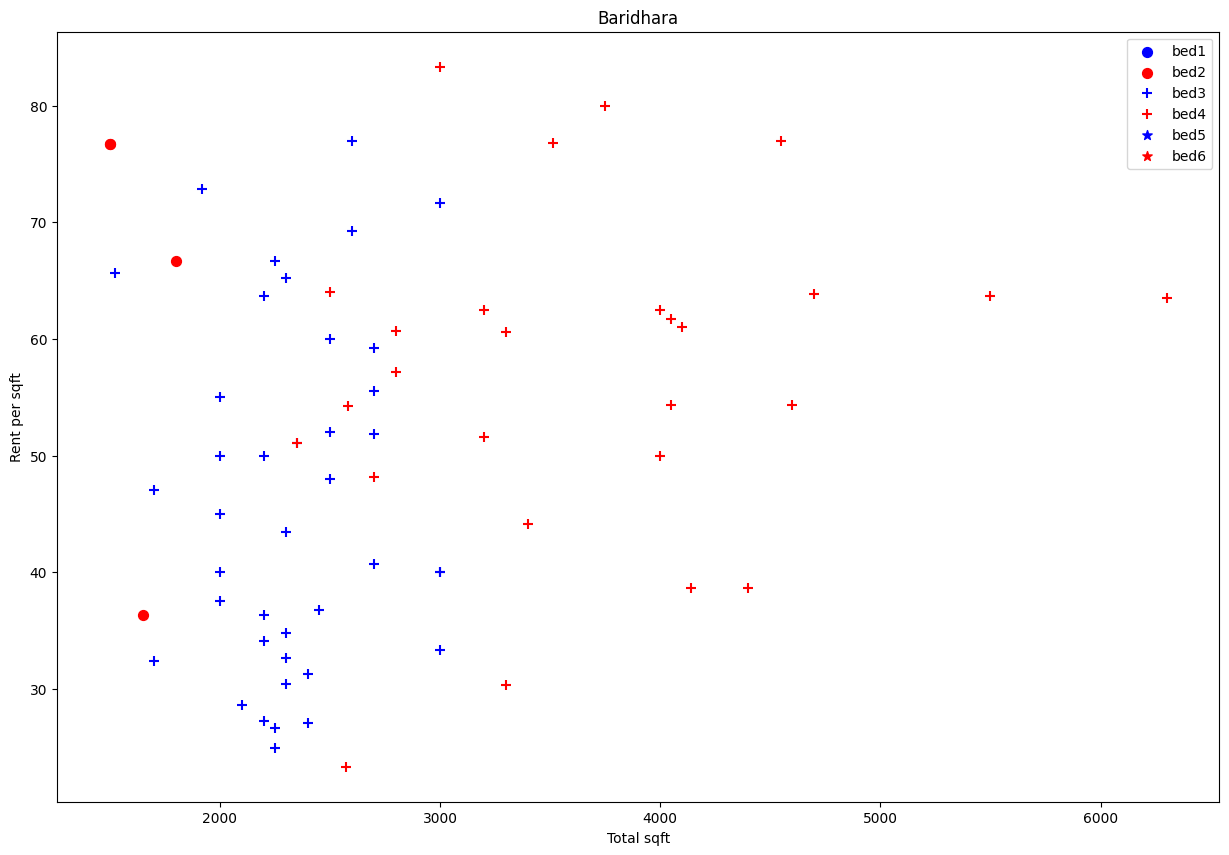

In [34]:
def plot_scatter(df, Location):
    bed1 = df[(df.Location == Location) & (df.Bed ==1)]
    bed2 = df[(df.Location == Location) & (df.Bed ==2)]
    bed3 = df[(df.Location == Location) & (df.Bed ==3)]
    bed4 = df[(df.Location == Location) & (df.Bed ==4)]
    bed5 = df[(df.Location == Location) & (df.Bed ==5)]
    bed6 = df[(df.Location == Location) & (df.Bed ==6)]
    matplotlib.rcParams['figure.figsize'] = (15,10)
    plt.scatter(bed1.Area, bed1.rent_per_sqft, color = 'blue', label='bed1',s=50)
    plt.scatter(bed2.Area, bed2.rent_per_sqft, color = 'red', label='bed2',s=50)
    plt.scatter(bed3.Area, bed3.rent_per_sqft, color = 'blue', label='bed3',marker='+',s=50)
    plt.scatter(bed4.Area, bed4.rent_per_sqft, color = 'red', label='bed4',marker='+',s=50)
    plt.scatter(bed5.Area, bed5.rent_per_sqft, color = 'blue', label='bed5',marker='*',s=50)
    plt.scatter(bed6.Area, bed6.rent_per_sqft, color = 'red', label='bed6',marker='*',s=50)
    plt.xlabel("Total sqft")
    plt.ylabel("Rent per sqft")
    plt.title(Location)
    plt.legend()

plot_scatter(df6, "Baridhara")

Text(0, 0.5, 'Count')

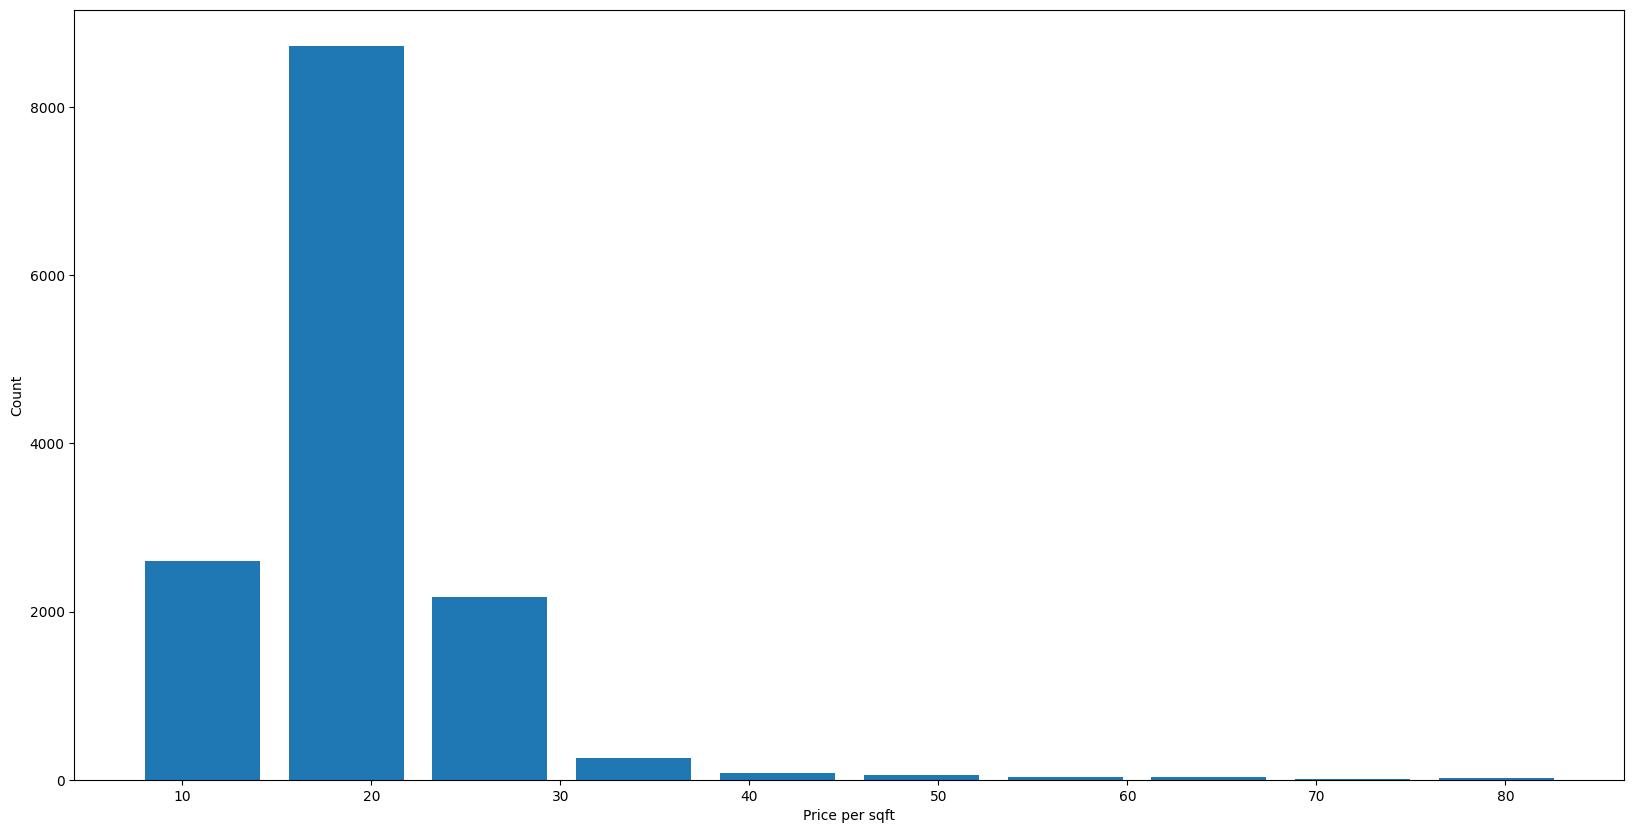

In [35]:
import matplotlib
matplotlib.rcParams["figure.figsize"] = (20,10)
plt.hist(df6.rent_per_sqft, rwidth=0.8)
plt.xlabel("Price per sqft")
plt.ylabel("Count")

In [36]:
df6.Bath.unique()

array([3, 2, 1, 4, 5, 6, 8])

In [37]:
df6[df6.Bath == 6]

,Location,Area,Bed,Bath,Rent_thousand,rent_per_sqft
5611,"Gulshan 2, Gulshan",4500,6,6,280.0,62.222222
5625,"Gulshan 2, Gulshan",4300,5,6,280.0,65.116279
8163,"Mohammadi Housing LTD., Mohammadpur",2200,5,6,40.0,18.181818
10191,"Sector 1, Uttara",2750,5,6,75.0,27.272727
12648,"Tejturi Bazar, Tejgaon",2450,6,6,60.0,24.489796


In [38]:
df6[df6.Bath> df6.Bed+2].shape


(1, 6)

In [39]:
df7=df6[~(df6.Bath> df6.Bed+2)]
df7.shape

(13975, 6)

In [40]:
df8 = df7.drop(['rent_per_sqft'], axis='columns')
df8.head()

,Location,Area,Bed,Bath,Rent_thousand
0,"1st Colony, Mirpur",1200,3,3,16.0
1,"1st Colony, Mirpur",800,2,2,13.5
2,"1st Colony, Mirpur",700,2,2,12.0
3,"1st Colony, Mirpur",1100,3,3,20.0
4,"1st Colony, Mirpur",1020,3,2,15.0


In [41]:
dummies = pd.get_dummies(df8.Location)
dummies.head(3)

,"1st Colony, Mirpur","2nd Colony, Mirpur","3rd Colony, Mirpur","Aainusbag, Dakshin Khan","Abdullahbag, Uttar Badda, Badda","Abdur Rafique Housing Society, Shekhertek, Mohammadpur",Adabor,"Adarsha Nagar, Badda",Agargaon,"Ahmed Nagar, Mirpur",...,"West Mollartek, Dakshin Khan","West Monipur, Mirpur","West Nakhalpara, Tejgaon","West Nandipara, Khilgaon","West Rampura, Rampura","West Shewrapara, Mirpur","West Vatara, Vatara, Badda","Zafrabad, Hazaribag","aziz Moholla, Mohammadpur",other
0,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [42]:
df9 = df8.drop('Location', axis='columns')

# Join column-wise using axis=1 and drop the 'other' dummy column to avoid multicollinearity
df10 = pd.concat([df9, dummies.drop('other', axis='columns')], axis=1)

df10.head(3)

,Area,Bed,Bath,Rent_thousand,"1st Colony, Mirpur","2nd Colony, Mirpur","3rd Colony, Mirpur","Aainusbag, Dakshin Khan","Abdullahbag, Uttar Badda, Badda","Abdur Rafique Housing Society, Shekhertek, Mohammadpur",...,"West Malibag, Malibagh","West Mollartek, Dakshin Khan","West Monipur, Mirpur","West Nakhalpara, Tejgaon","West Nandipara, Khilgaon","West Rampura, Rampura","West Shewrapara, Mirpur","West Vatara, Vatara, Badda","Zafrabad, Hazaribag","aziz Moholla, Mohammadpur"
0,1200,3,3,16.0,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,800,2,2,13.5,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,700,2,2,12.0,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [43]:

x=df10.drop('Rent_thousand', axis = 'columns')
x.head()

,Area,Bed,Bath,"1st Colony, Mirpur","2nd Colony, Mirpur","3rd Colony, Mirpur","Aainusbag, Dakshin Khan","Abdullahbag, Uttar Badda, Badda","Abdur Rafique Housing Society, Shekhertek, Mohammadpur",Adabor,...,"West Malibag, Malibagh","West Mollartek, Dakshin Khan","West Monipur, Mirpur","West Nakhalpara, Tejgaon","West Nandipara, Khilgaon","West Rampura, Rampura","West Shewrapara, Mirpur","West Vatara, Vatara, Badda","Zafrabad, Hazaribag","aziz Moholla, Mohammadpur"
0,1200,3,3,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,800,2,2,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,700,2,2,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,1100,3,3,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,1020,3,2,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [44]:
y = df10.Rent_thousand
y.head()

0    16.0
1    13.5
2    12.0
3    20.0
4    15.0
Name: Rent_thousand, dtype: float64

In [45]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=10)

In [46]:

from sklearn.linear_model import LinearRegression
lr_clf = LinearRegression()
lr_clf.fit(x_train, y_train)
print(lr_clf.score(x_test,y_test))
lr = lr_clf.predict(x_test)

0.8322441341182516


In [47]:

from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
kf = KFold(n_splits = 5, shuffle=True, random_state=42)

cross_val_score(LinearRegression(), x,y, cv=kf)


array([0.82105968, 0.83778769, 0.82203809, 0.85210606, 0.86259268])

In [48]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
print("R2: ", r2_score(y_test, lr))
print("MAE:", mean_absolute_error(y_test, lr))
print("RMSE:", mean_squared_error(y_test, lr) ** 0.5)

R2:  0.8322441341182516
MAE: 4.193327504555011
RMSE: 9.221610719626085


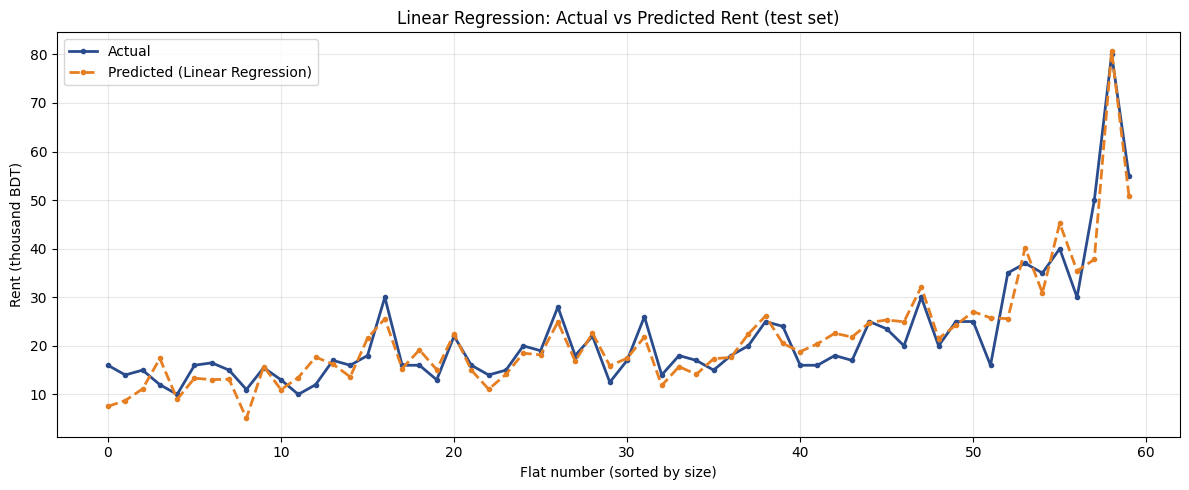

In [49]:

model = LinearRegression()
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

# actual and predicted side by side
compare = pd.DataFrame({"Area": x_test["Area"].values,
                        "Actual": y_test.values,
                        "Predicted": y_pred})

# pick 60 random test flats, then sort by size so the line is easy to read
sample = compare.sample(60, random_state=1).sort_values("Area").reset_index(drop=True)

plt.figure(figsize=(12, 5))
plt.plot(sample.index, sample["Actual"], color="#2b4c8c", marker="o", markersize=3,
         lw=2, label="Actual")
plt.plot(sample.index, sample["Predicted"], color="#e67e22", marker="o", markersize=3,
         lw=2, ls="--", label="Predicted (Linear Regression)")
plt.title("Linear Regression: Actual vs Predicted Rent (test set)")
plt.xlabel("Flat number (sorted by size)")
plt.ylabel("Rent (thousand BDT)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [50]:
#RandomForestRegressor
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=100, random_state=10).fit(x_train, y_train)
print(cross_val_score(RandomForestRegressor(n_estimators=100, random_state=10), x,y, cv=kf))
r = rf.predict(x_test)

print("R2:", r2_score(y_test, r))
print("MAE:", mean_absolute_error(y_test, r))
print("RMSE:", mean_squared_error(y_test, r) ** 0.5)


[0.86111931 0.88728303 0.86290965 0.89342689 0.87626798]
R2: 0.8600828307994944
MAE: 3.6976343749355283
RMSE: 8.42177108360494


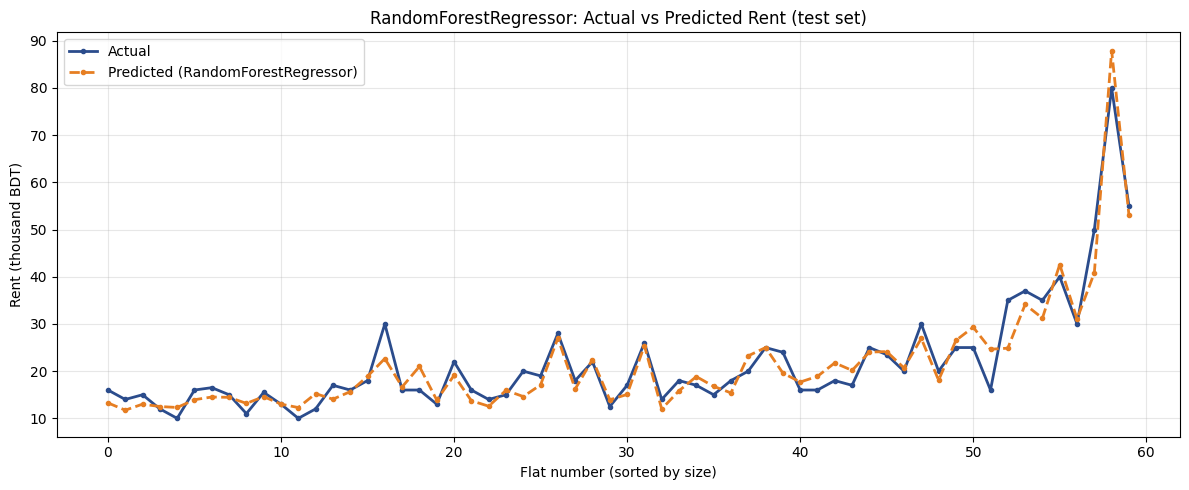

In [51]:
model = RandomForestRegressor(n_estimators=100, random_state=10)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

# actual and predicted side by side
compare = pd.DataFrame({"Area": x_test["Area"].values,
                        "Actual": y_test.values,
                        "Predicted": y_pred})

# pick 60 random test flats, then sort by size so the line is easy to read
sample = compare.sample(60, random_state=1).sort_values("Area").reset_index(drop=True)

plt.figure(figsize=(12, 5))
plt.plot(sample.index, sample["Actual"], color="#2b4c8c", marker="o", markersize=3,
         lw=2, label="Actual")
plt.plot(sample.index, sample["Predicted"], color="#e67e22", marker="o", markersize=3,
         lw=2, ls="--", label="Predicted (RandomForestRegressor)")
plt.title("RandomForestRegressor: Actual vs Predicted Rent (test set)")
plt.xlabel("Flat number (sorted by size)")
plt.ylabel("Rent (thousand BDT)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [52]:
#Lasso
from sklearn.linear_model import Lasso
print(cross_val_score(Lasso(alpha=0.01, max_iter=10000),x,y,cv=kf))
ls = Lasso(alpha=0.01, max_iter=10000).fit(x_train, y_train)
l = ls.predict(x_test)
print("R2:", r2_score(y_test, l))
print("MAE:", mean_absolute_error(y_test, l))
print("RMSE:", mean_squared_error(y_test, l) ** 0.5)


[0.81291643 0.82830005 0.8143943  0.83824427 0.85532806]
R2: 0.8244705653774678
MAE: 4.5667382189595225
RMSE: 9.43284948079281


In [53]:
from sklearn.linear_model import Ridge
print(cross_val_score(Ridge(alpha=1.0),x,y,cv=kf))
ri = Ridge()

[0.82254146 0.83783095 0.82328025 0.85054368 0.86240927]


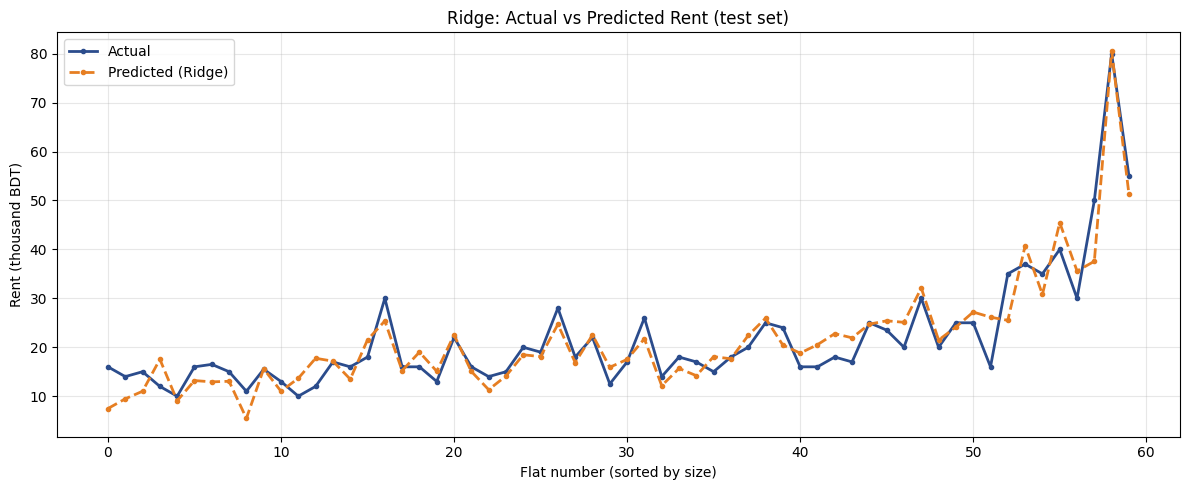

In [54]:
model = Ridge(alpha=1.0)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

# actual and predicted side by side
compare = pd.DataFrame({"Area": x_test["Area"].values,
                        "Actual": y_test.values,
                        "Predicted": y_pred})

# pick 60 random test flats, then sort by size so the line is easy to read
sample = compare.sample(60, random_state=1).sort_values("Area").reset_index(drop=True)

plt.figure(figsize=(12, 5))
plt.plot(sample.index, sample["Actual"], color="#2b4c8c", marker="o", markersize=3,
         lw=2, label="Actual")
plt.plot(sample.index, sample["Predicted"], color="#e67e22", marker="o", markersize=3,
         lw=2, ls="--", label="Predicted (Ridge)")
plt.title("Ridge: Actual vs Predicted Rent (test set)")
plt.xlabel("Flat number (sorted by size)")
plt.ylabel("Rent (thousand BDT)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [55]:
from sklearn.tree import DecisionTreeRegressor
dt = DecisionTreeRegressor(max_depth=20, random_state=10).fit(x_train, y_train)
print(cross_val_score(DecisionTreeRegressor(max_depth=20, random_state=10), x,y, cv=kf))
dp = dt.predict(x_test)

print("R2:", r2_score(y_test, dp))
print("MAE:", mean_absolute_error(y_test, dp))
print("RMSE:", mean_squared_error(y_test, dp) ** 0.5)

[0.81294775 0.85879666 0.76314834 0.85431062 0.81993296]
R2: 0.7937071354277512
MAE: 4.323559474339814
RMSE: 10.226099892141528


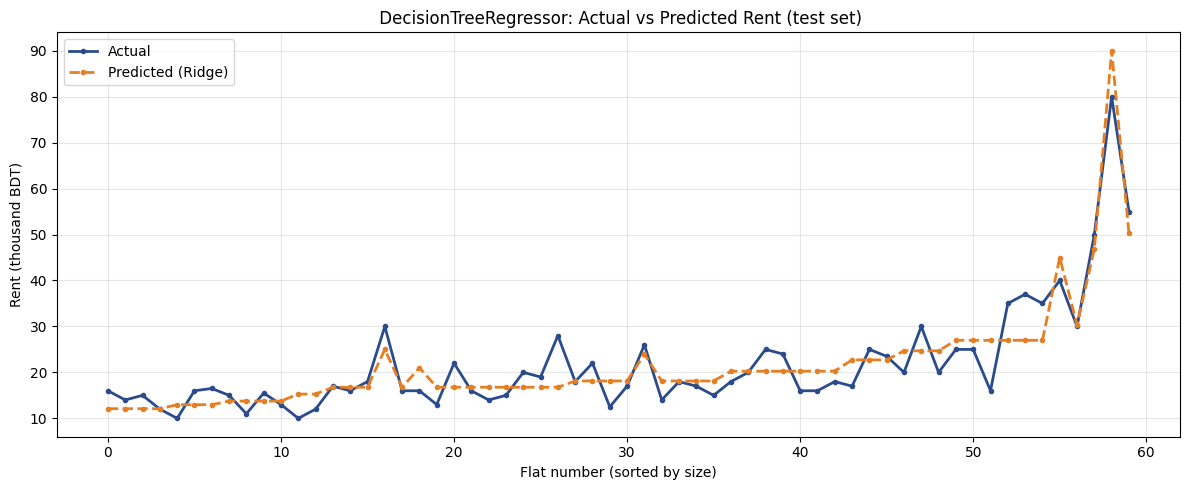

In [56]:
model = DecisionTreeRegressor(max_depth=20, random_state=10)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

# actual and predicted side by side
compare = pd.DataFrame({"Area": x_test["Area"].values,
                        "Actual": y_test.values,
                        "Predicted": y_pred})

# pick 60 random test flats, then sort by size so the line is easy to read
sample = compare.sample(60, random_state=1).sort_values("Area").reset_index(drop=True)

plt.figure(figsize=(12, 5))
plt.plot(sample.index, sample["Actual"], color="#2b4c8c", marker="o", markersize=3,
         lw=2, label="Actual")
plt.plot(sample.index, sample["Predicted"], color="#e67e22", marker="o", markersize=3,
         lw=2, ls="--", label="Predicted (Ridge)")
plt.title(" DecisionTreeRegressor: Actual vs Predicted Rent (test set)")
plt.xlabel("Flat number (sorted by size)")
plt.ylabel("Rent (thousand BDT)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()